In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
covid = pd.read_csv(
    "../data/processed/covid_cleaned.csv",
    parse_dates = ["date"] 
)

In [3]:
covid.head()

,date,country,confirmed,deaths,recovered,active,new_cases,new_deaths,new_recovered,who_region,continent,population
0,2020-01-22,Afghanistan,0,0,0,0.0,0,0,0,Eastern Mediterranean,Asia,39009447.0
1,2020-01-22,Albania,0,0,0,0.0,0,0,0,Europe,Europe,2877470.0
2,2020-01-22,Algeria,0,0,0,0.0,0,0,0,Africa,Africa,43926079.0
3,2020-01-22,Andorra,0,0,0,0.0,0,0,0,Europe,Europe,77278.0
4,2020-01-22,Angola,0,0,0,0.0,0,0,0,Africa,Africa,32956300.0


In [4]:
covid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35156 entries, 0 to 35155
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           35156 non-null  datetime64[ns]
 1   country        35156 non-null  object        
 2   confirmed      35156 non-null  int64         
 3   deaths         35156 non-null  int64         
 4   recovered      35156 non-null  int64         
 5   active         35154 non-null  float64       
 6   new_cases      35156 non-null  int64         
 7   new_deaths     35156 non-null  int64         
 8   new_recovered  35156 non-null  int64         
 9   who_region     35156 non-null  object        
 10  continent      35156 non-null  object        
 11  population     34780 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(6), object(3)
memory usage: 3.2+ MB


In [5]:
print("Start date:", covid["date"].min())
print("End date:", covid["date"].max())
print("Countries:", covid["country"].nunique())

Start date: 2020-01-22 00:00:00
End date: 2020-07-27 00:00:00
Countries: 187


In [6]:
latest_date = covid["date"].max()
latest = covid[covid["date"] == latest_date].copy()
latest.head()

,date,country,confirmed,deaths,recovered,active,new_cases,new_deaths,new_recovered,who_region,continent,population
34969,2020-07-27,Afghanistan,36263,1269,25198,9796.0,106,10,18,Eastern Mediterranean,Asia,39009447.0
34970,2020-07-27,Albania,4880,144,2745,1991.0,117,6,63,Europe,Europe,2877470.0
34971,2020-07-27,Algeria,27973,1163,18837,7973.0,616,8,749,Africa,Africa,43926079.0
34972,2020-07-27,Andorra,907,52,803,52.0,10,0,0,Europe,Europe,77278.0
34973,2020-07-27,Angola,950,41,242,667.0,18,1,0,Africa,Africa,32956300.0


In [7]:
latest.shape

(187, 12)

In [8]:
total_confirmed = latest["confirmed"].sum()
total_deaths = latest["deaths"].sum()
total_recovered = latest["recovered"].sum()
total_active = latest["active"].sum(min_count = 1)

In [9]:
print(f"Confirmed cases: {total_confirmed:,}")
print(f"Total deaths: {total_deaths:,}")
print(f"Total recovered: {total_recovered:,}")
print(f"Active cases: {total_active:,.0f}")

Confirmed cases: 16,480,485
Total deaths: 654,036
Total recovered: 9,468,087
Active cases: 6,358,362


In [10]:
fatality_rate = (total_deaths / total_confirmed) * 100

In [11]:
recovery_rate = (total_recovered / total_confirmed) * 100

In [12]:
active_rate = (total_active / total_confirmed) * 100

In [13]:
print(f"Case fatality ratio: {fatality_rate:.2f}%")
print(f"Recovery rate: {recovery_rate:.2f}%")
print(f"Active case percentage: {active_rate:.2f}%")

Case fatality ratio: 3.97%
Recovery rate: 57.45%
Active case percentage: 38.58%


In [14]:
top10_cases = latest.nlargest(10, "confirmed")
top10_cases[["country", "confirmed"]]

,country,confirmed
35142,US,4290259
34992,Brazil,2442375
35048,India,1480073
35107,Russia,816680
35123,South Africa,452529
35080,Mexico,395489
35101,Peru,389717
35004,Chile,347923
35146,United Kingdom,301708
35050,Iran,293606


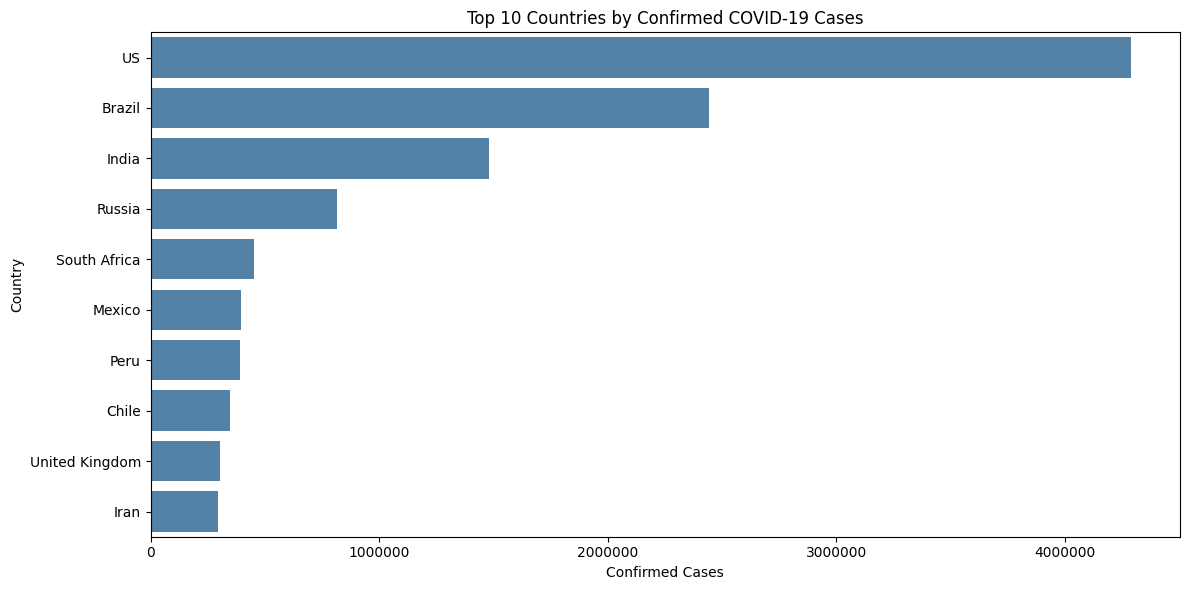

In [15]:
plt.figure(figsize = (12,6 ))

sns.barplot(
    data = top10_cases, 
    x = "confirmed",
    y = "country",
    color = "steelblue" 
)

plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")

plt.ticklabel_format(style = "plain", axis = "x")
plt.tight_layout()
plt.show()

In [16]:
top10_share = (
    top10_cases["confirmed"].sum() / total_confirmed
) * 100 

print(f"Top 10 countries share: {top10_share:.2f}%")

Top 10 countries share: 68.02%


### Key Finding 1 

As of July 27, 2020, the top 10 countries accounted for 68.02% of global confirmed COVID-19 cases, indicating a high geographical concentration of reported cases

In [17]:
top10_deaths = latest.nlargest(10, "deaths")

top10_deaths[["country", "deaths"]]

,country,deaths
35142,US,148011
34992,Brazil,87618
35146,United Kingdom,45844
35080,Mexico,44022
35054,Italy,35112
35048,India,33408
35030,France,30212
35126,Spain,28432
35101,Peru,18418
35050,Iran,15912


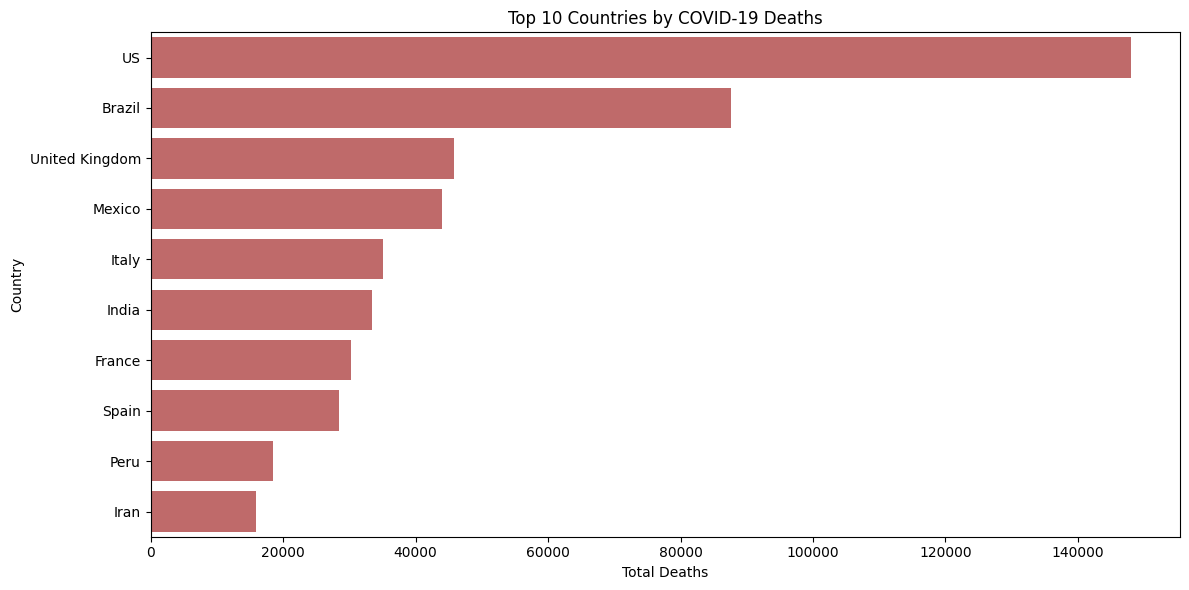

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10_deaths,
    x="deaths",
    y="country",
    color="indianred"
)

plt.title("Top 10 Countries by COVID-19 Deaths")
plt.xlabel("Total Deaths")
plt.ylabel("Country")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [19]:
top10_death_share = (
    top10_deaths["deaths"].sum() / total_deaths
) * 100

print(f"Top 10 countries' death share: {top10_death_share:.2f}%")

Top 10 countries' death share: 74.46%


### Key Finding 2 

As of July 27, 2020, the top 10 countries by reported COVID-19 deaths accounted for 74.46% of global deaths. This exceeded the 68.02% share of confirmed cases among the top 10 countries by cases count, indicating a greater geographical conceentration of reported deaths.

In [20]:
global_daily = covid.groupby("date")[
    ["confirmed", "deaths", "recovered", "new_cases", "new_deaths", "new_recovered"]
].sum().reset_index()

global_daily.head()

,date,confirmed,deaths,recovered,new_cases,new_deaths,new_recovered
0,2020-01-22,555,17,28,0,0,0
1,2020-01-23,654,18,30,99,1,2
2,2020-01-24,941,26,36,287,8,6
3,2020-01-25,1434,42,39,493,16,3
4,2020-01-26,2118,56,52,684,14,13


In [21]:
global_daily.shape 

(188, 7)

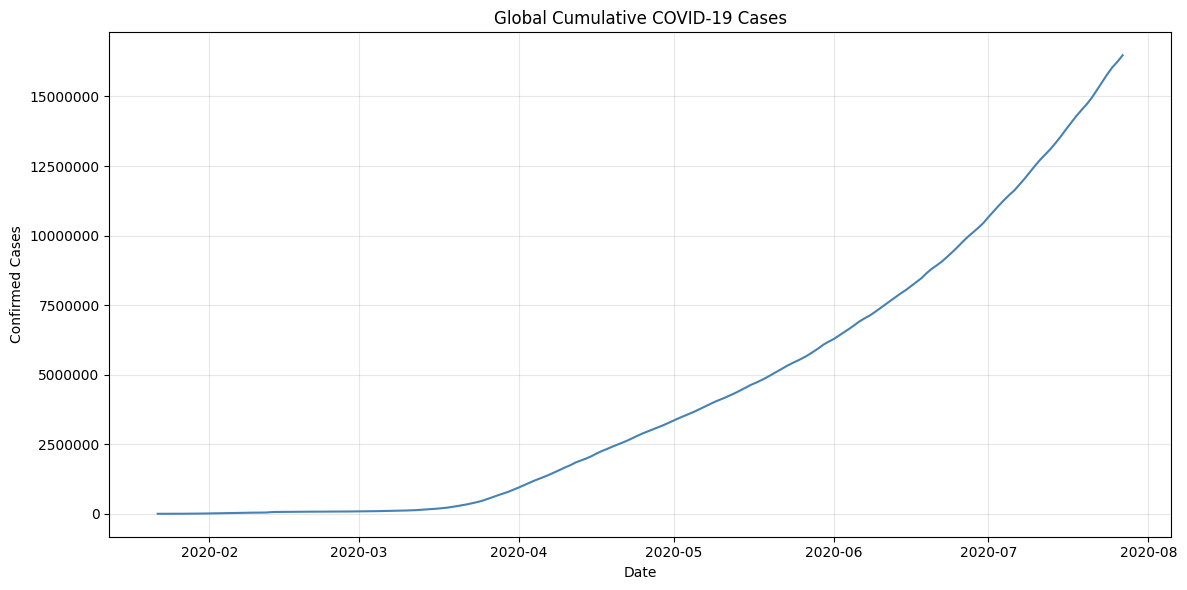

In [22]:
plt.figure(figsize = (12,6))

plt.plot(
    global_daily["date"],
    global_daily["confirmed"],
    color = "steelblue" 
)

plt.title("Global Cumulative COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")

plt.ticklabel_format(style = "plain", axis = "y")
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

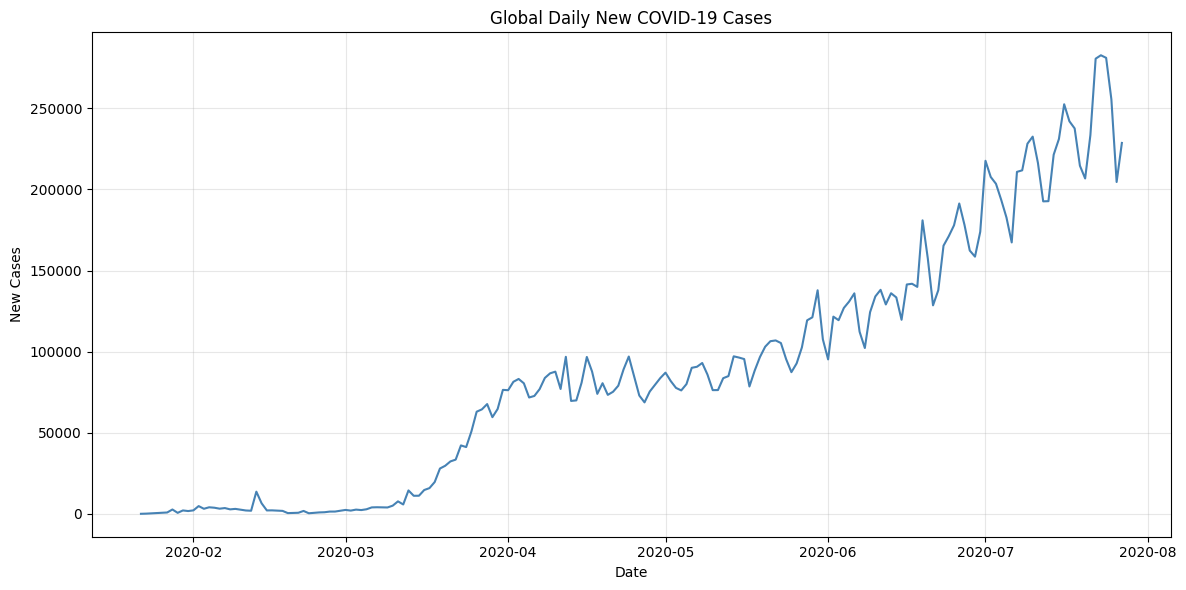

In [23]:
plt.figure(figsize = (12, 6))

plt.plot(
    global_daily["date"],
    global_daily["new_cases"],
    color = "steelblue" 
)

plt.title("Global Daily New COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("New Cases")

plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

In [24]:
global_daily["new_cases_7day_avg"] = (
    global_daily["new_cases"].rolling(window = 7).mean()
)

In [25]:
global_daily[["date", "new_cases", "new_cases_7day_avg"]].head(10)

,date,new_cases,new_cases_7day_avg
0,2020-01-22,0,NaN
1,2020-01-23,99,NaN
2,2020-01-24,287,NaN
3,2020-01-25,493,NaN
4,2020-01-26,684,NaN
5,2020-01-27,809,NaN
6,2020-01-28,2651,717.571429
7,2020-01-29,588,801.571429
8,2020-01-30,2068,1082.857143
9,2020-01-31,1693,1283.714286


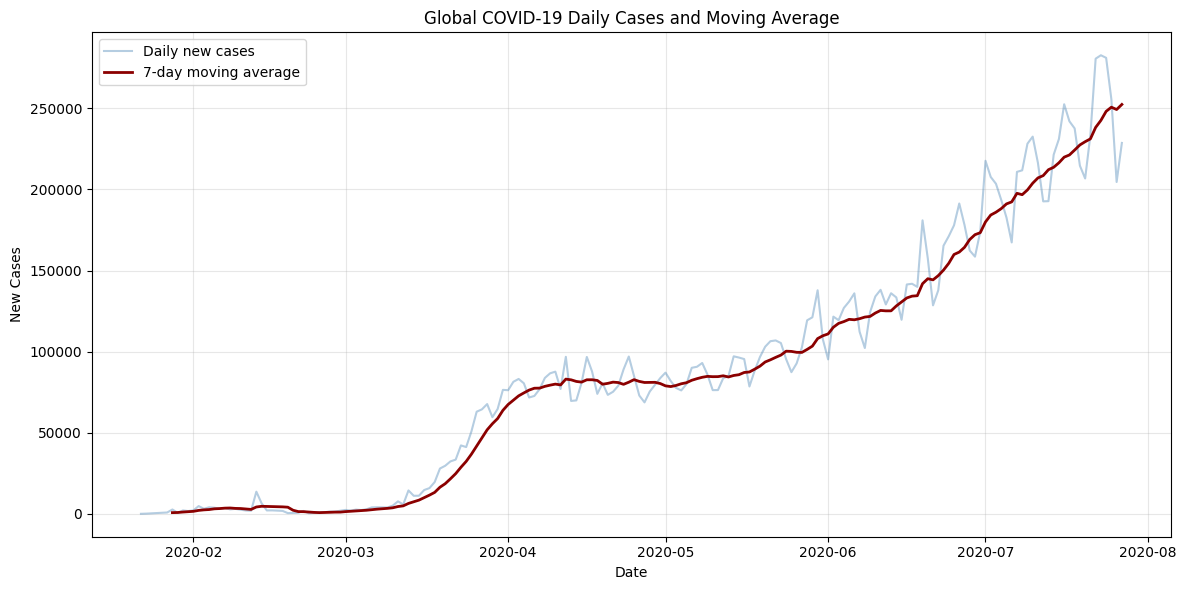

In [26]:
plt.figure(figsize=(12,6))

plt.plot(
    global_daily["date"],
    global_daily["new_cases"],
    color = "steelblue",
    alpha = 0.4,
    label = "Daily new cases" 
)

plt.plot(
    global_daily["date"],
    global_daily["new_cases_7day_avg"],
    color = "darkred",
    linewidth = 2,
    label = "7-day moving average"
)

plt.title("Global COVID-19 Daily Cases and Moving Average")
plt.xlabel("Date")
plt.ylabel("New Cases")

plt.legend()
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

In [27]:
global_daily.nlargest(1, "new_cases")[
    ["date", "new_cases"]
]

,date,new_cases
183,2020-07-23,282756


### Key Finding 3 

Global daily COVID-19 cases increases significantly from March to July 2020, reaching a peak of 282,756 reported cases on July 23, 2020. 

The seven-day moving average reveals a sustained upward trend from June onward despite daily reported fluctuations.

In [28]:
continent_summary = latest.groupby("continent")[
    ["confirmed", "deaths", "recovered", "active"]
].sum().reset_index()

continent_summary = continent_summary.sort_values(
    "confirmed", ascending = False 
)

continent_summary

,continent,confirmed,deaths,recovered,active
4,North America,5058816,207226,1754456,3097134.0
1,Asia,3971615,91135,2871259,1009221.0
5,South America,3780484,135506,2714173,930805.0
3,Europe,2792084,201804,1611116,979164.0
0,Africa,860537,18176,506229,336132.0
2,Australia/Oceania,16949,189,10854,5906.0


In [29]:
continent_summary["fatality_rate"] = (
    continent_summary["deaths"] / continent_summary["confirmed"]
) * 100

continent_summary["case_share"] = (
    continent_summary["confirmed"] / total_confirmed 
) * 100

continent_summary

,continent,confirmed,deaths,recovered,active,fatality_rate,case_share
4,North America,5058816,207226,1754456,3097134.0,4.096334,30.695796
1,Asia,3971615,91135,2871259,1009221.0,2.294658,24.098896
5,South America,3780484,135506,2714173,930805.0,3.584356,22.939155
3,Europe,2792084,201804,1611116,979164.0,7.227720,16.941759
0,Africa,860537,18176,506229,336132.0,2.112169,5.221551
2,Australia/Oceania,16949,189,10854,5906.0,1.115110,0.102843


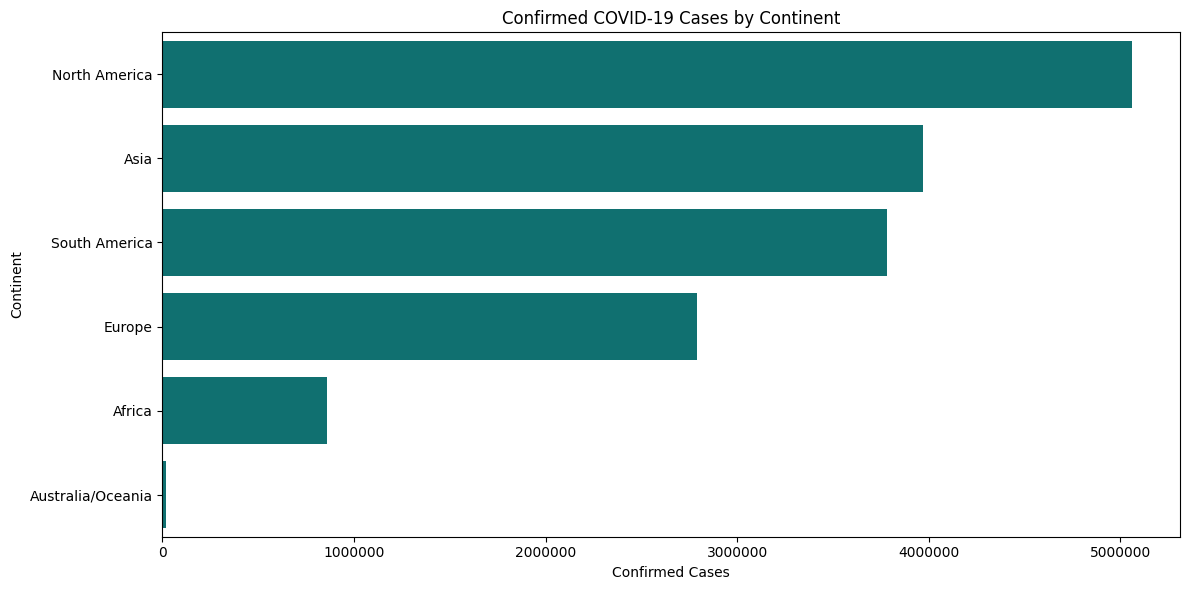

In [30]:
plt.figure(figsize = (12,6))

sns.barplot(
    data = continent_summary,
    x = "confirmed",
    y = "continent",
    color = "teal" 
)

plt.title("Confirmed COVID-19 Cases by Continent")
plt.xlabel("Confirmed Cases")
plt.ylabel("Continent")

plt.ticklabel_format(style = "plain", axis = "x")
plt.tight_layout()
plt.show()

In [31]:
population_analysis = latest[
    latest["population"].notna() & 
    (latest["population"] > 0)
].copy()

population_analysis.shape

(185, 12)

In [32]:
population_analysis["cases_per_100k"] = (
    population_analysis["confirmed"] / population_analysis["population"]
) * 100000

In [33]:
population_analysis["deaths_per_100k"] = (
    population_analysis["deaths"] / population_analysis["population"]
) * 100000

In [34]:
top10_per_capita = population_analysis.nlargest(
    10, "cases_per_100k" 
)

top10_per_capita[
    ["country", "population", "confirmed", "cases_per_100k"]
]

,country,population,confirmed,cases_per_100k
35105,Qatar,2807805.0,109597,3903.298128
34981,Bahrain,1706669.0,39482,2313.395275
35112,San Marino,33938.0,699,2059.638164
35004,Chile,19132514.0,347923,1818.490764
35096,Oman,5118446.0,77058,1505.496004
35061,Kuwait,4276658.0,64379,1505.357688
35044,Holy See,801.0,12,1498.127341
35098,Panama,4321282.0,61442,1421.846572
35142,US,331198130.0,4290259,1295.375369
34976,Armenia,2963811.0,37390,1261.551428


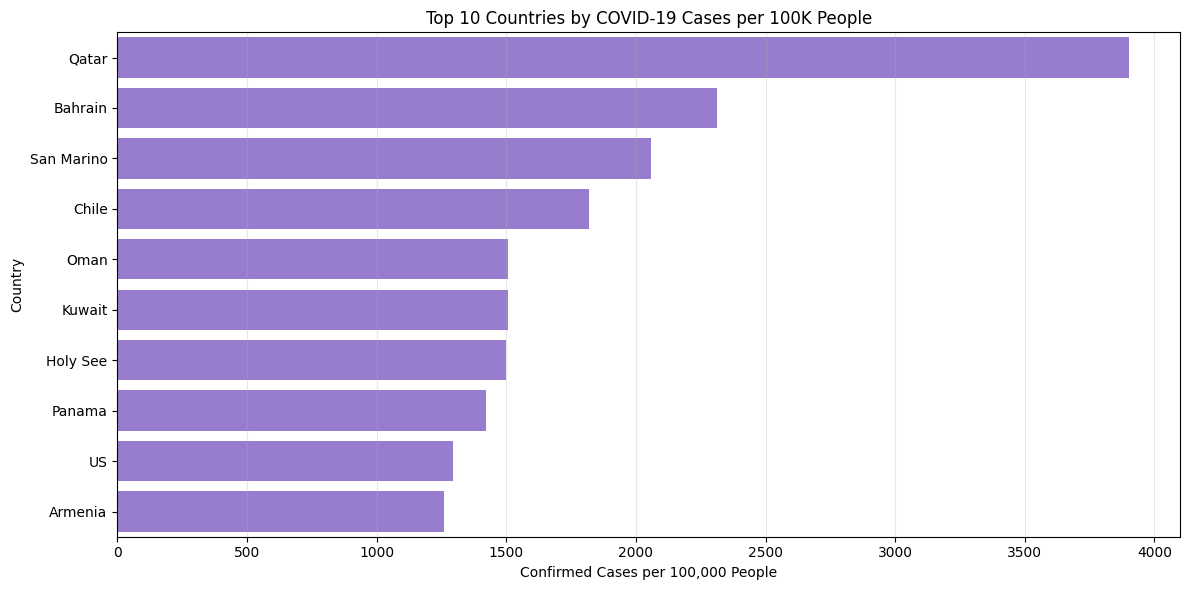

In [35]:
plt.figure(figsize = (12, 6))

sns.barplot(
    data = top10_per_capita,
    x = "cases_per_100k",
    y = "country",
    color = "mediumpurple" 
)

plt.title("Top 10 Countries by COVID-19 Cases per 100K People")
plt.xlabel("Confirmed Cases per 100,000 People")
plt.ylabel("Country") 

plt.grid(axis = "x", alpha = 0.3)
plt.tight_layout()
plt.show()

In [36]:
top10_deaths_per_capita = population_analysis.nlargest(
    10, "deaths_per_100k" 
)

top10_deaths_per_capita[
    ["country", "population", "deaths", "deaths_per_100k"]
]

,country,population,deaths,deaths_per_100k
35112,San Marino,33938.0,42,123.755083
34985,Belgium,11594739.0,9822,84.710833
35146,United Kingdom,67922029.0,45844,67.495039
34972,Andorra,77278.0,52,67.289526
35126,Spain,46756648.0,28432,60.808465
35054,Italy,60452568.0,35112,58.081900
35130,Sweden,10105596.0,5700,56.404392
35101,Peru,33016319.0,18418,55.784535
35004,Chile,19132514.0,9187,48.017736
35030,France,65288306.0,30212,46.274749


### Key Finding 5

Although the United States recorded the highest number of COVID-19 cases, Qatar had the highest population-adjusted case count at approximately 3,903 cases per 100,000 people. 

San Marino recorded the highest population-adjusted death count at approximately 124 deaths per 100,000 people among countries with available population data.

These findins demonstrate the importance of population normalization when comparing countries